## 3.0. Cargar datos

Primero utilizando la lógica del módulo 2 se adquieren los datos filtrados de la carpeta 

In [2]:
%load_ext autoreload
%autoreload 2

import sys
import os
# --- Subir un nivel (..) para encontrar procesamiento_eeg.py en la raíz ---
sys.path.append(os.path.abspath('..'))

# --- Imports ---
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import procesamiento_eeg as eeg
import random
import analisis_PSD as PSD

# --- Ruta a la carpeta ---
ruta_datos = '../datos/Datos_Filtrados'

df_reporte = eeg.auditar_dataset_segmentado(ruta_datos)
sujetos_excluidos = ['s19']

lista_archivos = [
    a for a in df_reporte['archivo'] 
    if not any(a.startswith(s) for s in sujetos_excluidos)
]
print(lista_archivos[0])

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
--- Auditoría de calidad sobre 38 archivos ---

Resumen del Control de Calidad:
Archivos válidos: 38 / 38
Todos los archivos pasaron el control de calidad perfectamente
s01_ex05.csv


## 3.2.Lectura de datos y PSD

Leemos el archivo y usando Welch de manera manual  del archivo /analisis_PSD y graficamos los cuatro canales para todos los sujetos, primero para el experimento 5 que es el sujeto escuchando la canción en idioma nativo

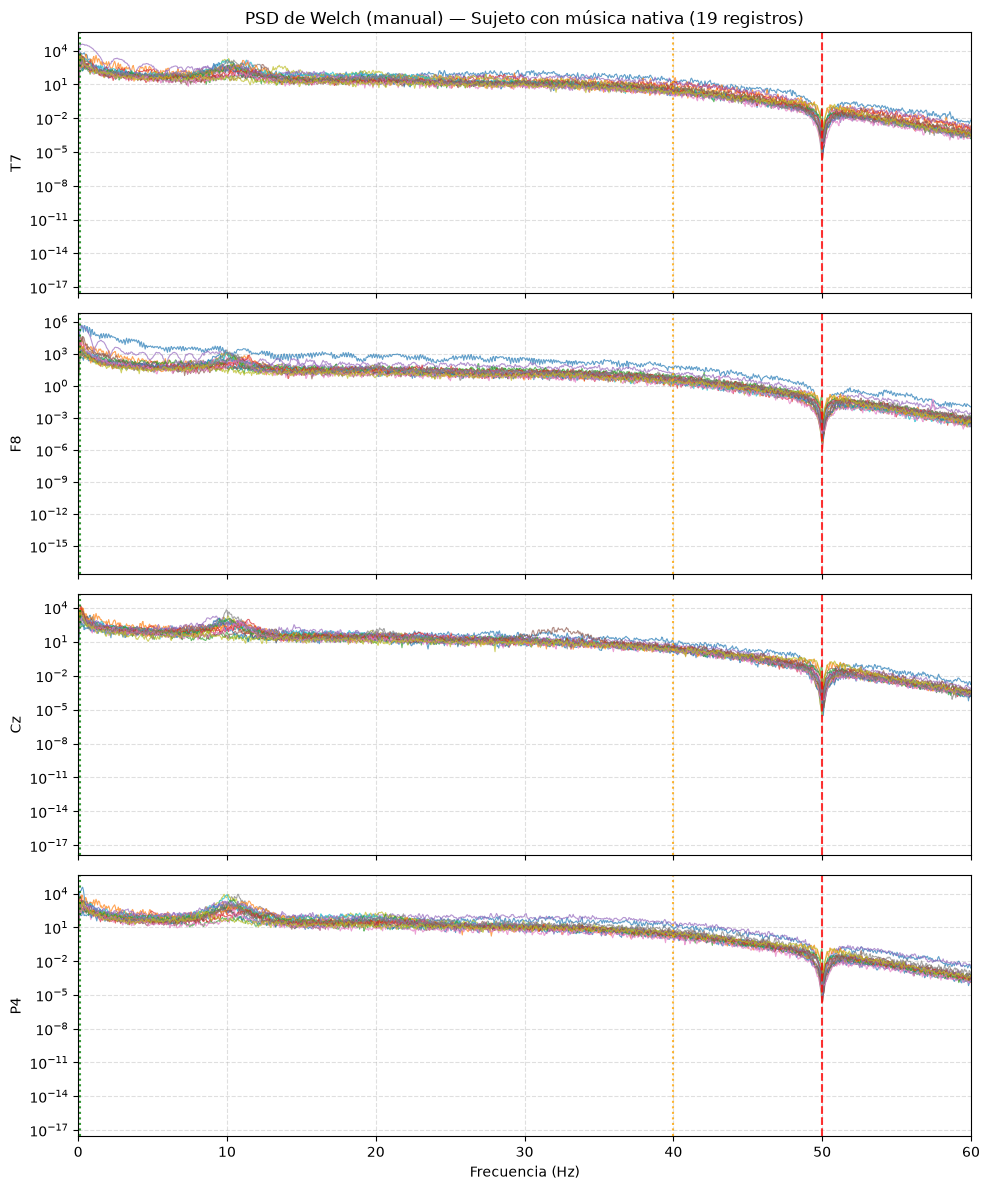

In [3]:
fs = 200
nperseg = 4000
archivos_ex05 = [a for a in lista_archivos if "ex05" in a]
canales = ["T7", "F8", "Cz", "P4"]  # ajustá si tus columnas tienen otro orden/nombre

fig, axes = plt.subplots(len(canales), 1, figsize=(10, 3 * len(canales)), sharex=True)

for nombre in archivos_ex05:
    path = os.path.join(ruta_datos, nombre)
    df = pd.read_csv(path, index_col=0)

    freq, psd_dict = PSD.welch_eeg(df, fs, nperseg=nperseg, canales=canales)

    for ax, canal in zip(axes, canales):
        ax.semilogy(freq, psd_dict[canal], lw=0.8, alpha=0.7, label=nombre)

for ax, canal in zip(axes, canales):
    for f_ref, (c, ls) in eeg.REFS_DEFAULT.items():
        ax.axvline(f_ref, color=c, ls=ls, alpha=0.8)
    ax.set_ylabel(canal)
    ax.set_xlim(0, 60)
    ax.grid(True, which="both", ls="--", alpha=0.4)

axes[0].set_title(f"PSD de Welch (manual) — Sujeto con música nativa ({len(archivos_ex05)} registros)")
axes[-1].set_xlabel("Frecuencia (Hz)")
plt.tight_layout()
plt.show()

Luego se realizó el mismo procedimiento para el ejercicio 6, que es el sujeto en música no nativa 

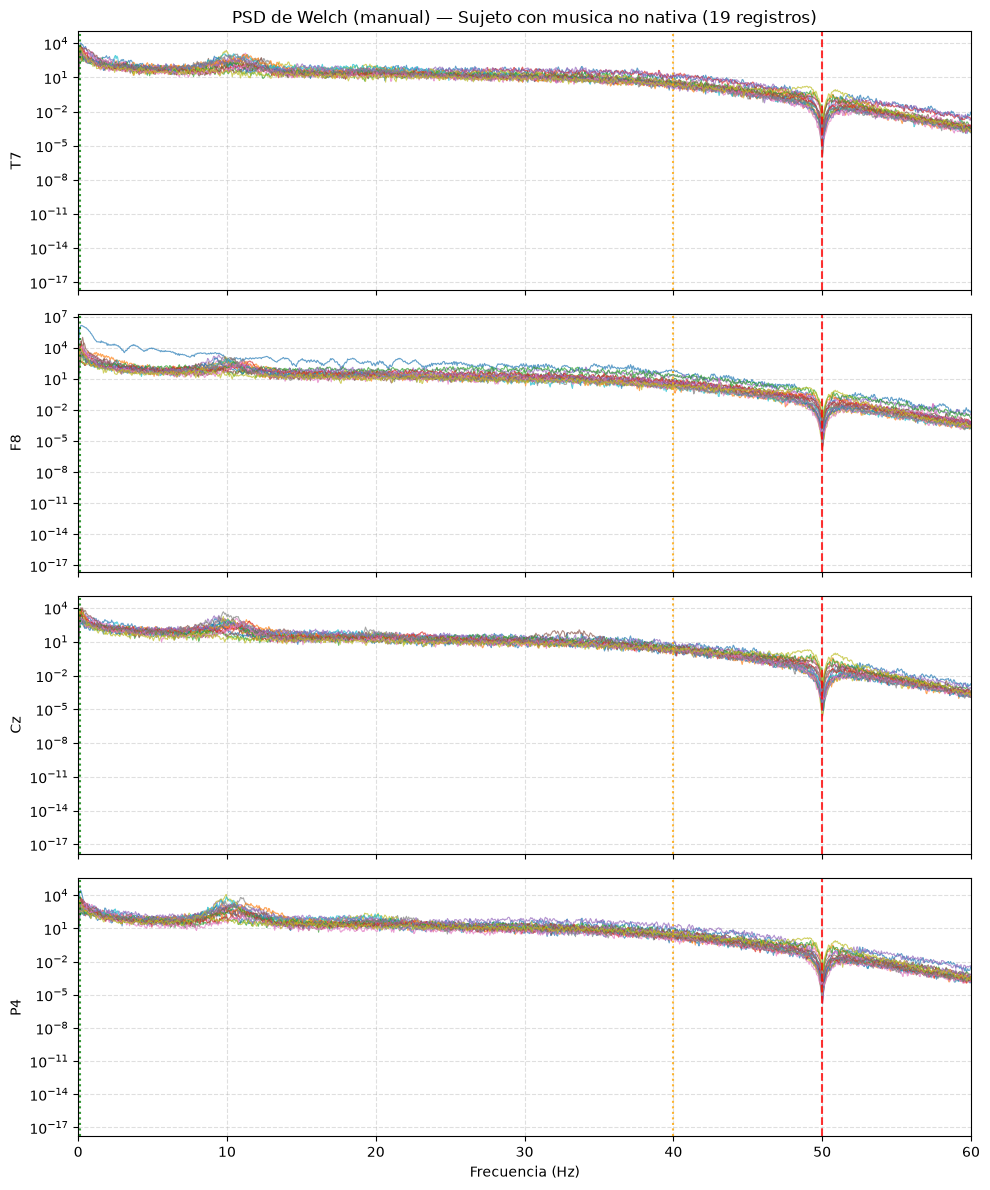

In [4]:
archivos_ex06 = [a for a in lista_archivos if "ex06" in a]
canales = ["T7", "F8", "Cz", "P4"]  # ajustá si tus columnas tienen otro orden/nombre

fig, axes = plt.subplots(len(canales), 1, figsize=(10, 3 * len(canales)), sharex=True)

for nombre in archivos_ex06:
    path = os.path.join(ruta_datos, nombre)
    df = pd.read_csv(path, index_col=0)

    freq, psd_dict = PSD.welch_eeg(df, fs, nperseg=nperseg, canales=canales)

    for ax, canal in zip(axes, canales):
        ax.semilogy(freq, psd_dict[canal], lw=0.8, alpha=0.7, label=nombre)

for ax, canal in zip(axes, canales):
    for f_ref, (c, ls) in eeg.REFS_DEFAULT.items():
        ax.axvline(f_ref, color=c, ls=ls, alpha=0.8)
    ax.set_ylabel(canal)
    ax.set_xlim(0, 60)
    ax.grid(True, which="both", ls="--", alpha=0.4)

axes[0].set_title(f"PSD de Welch (manual) — Sujeto con musica no nativa ({len(archivos_ex06)} registros)")
axes[-1].set_xlabel("Frecuencia (Hz)")
plt.tight_layout()
plt.show()

## 3.3 Mediana

Para estudiar mejor la PSD, se aplica la mediana para  tener solo una muestra. Se elije la mediana ya que esta es menos sensible a outlyers  y esto es bueno ya que la media se distorsiona mucho con los outlyers. en cambio la mediana no se mueve tanto porque no depende de la magnitud del valor extremo, solo de su posición relativa.

Primero realizamos esto para el experimento 5, que es los sujetos escuchando canciones en su idioma nativo

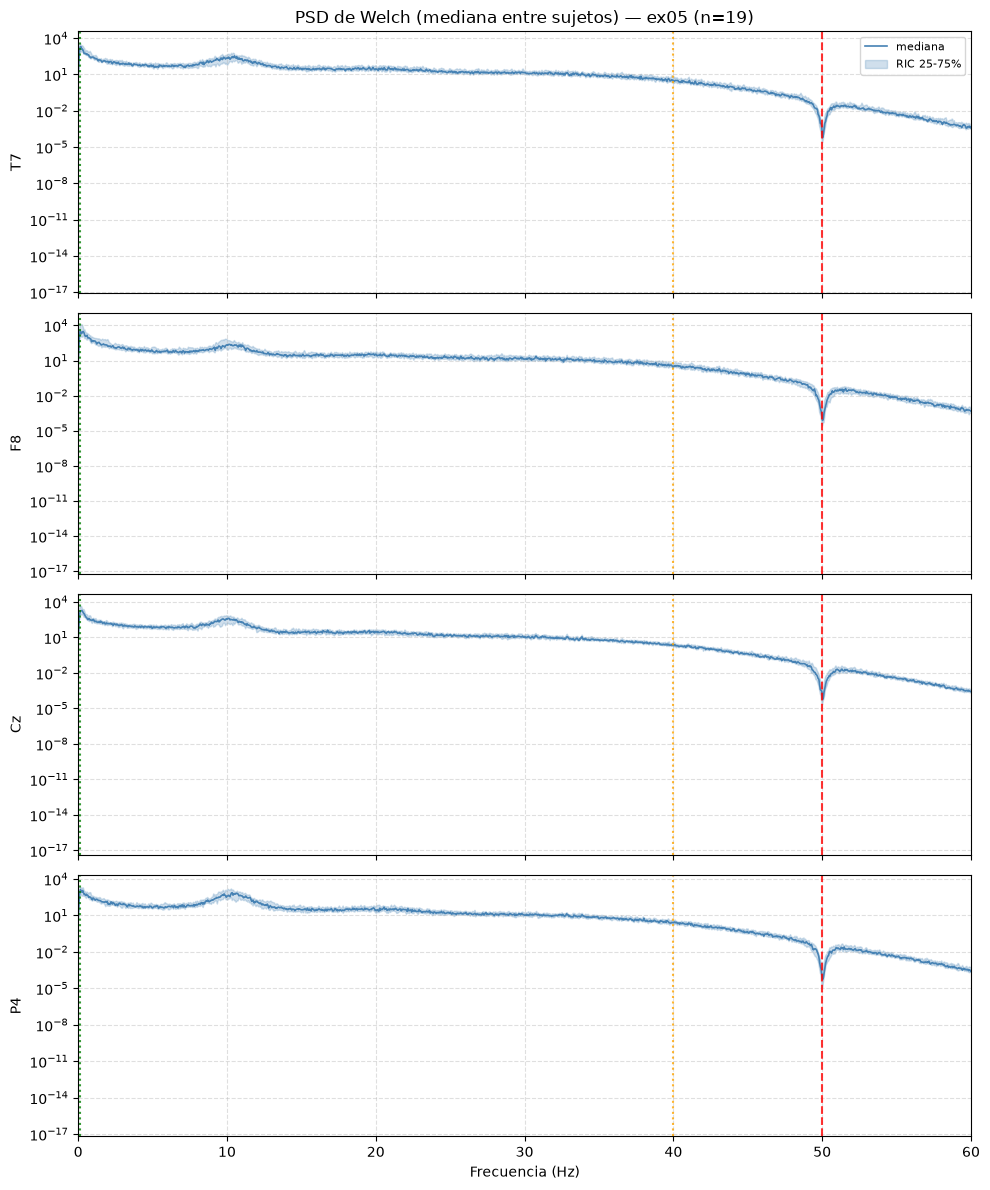

In [5]:
psd_acumulado = {canal: [] for canal in canales}
freq = None
for nombre in archivos_ex05:
    path = os.path.join(ruta_datos, nombre)
    df = pd.read_csv(path, index_col=0)

    f, psd_dict = PSD.welch_eeg(df, fs, nperseg=nperseg, canales=canales)
    if freq is None:
        freq = f

    for canal in canales:
        psd_acumulado[canal].append(psd_dict[canal])

# Convertir a matrices (sujetos x frecuencias) y calcular media/mediana + dispersión
fig, axes = plt.subplots(len(canales), 1, figsize=(10, 3 * len(canales)), sharex=True)

for ax, canal in zip(axes, canales):
    matriz = np.array(psd_acumulado[canal])  # shape: (n_sujetos, n_freq)

    mediana05 = np.median(matriz, axis=0)
    p25 = np.percentile(matriz, 25, axis=0)
    p75 = np.percentile(matriz, 75, axis=0)

    ax.semilogy(freq, mediana05, color="steelblue", lw=1.2, label="mediana")
    ax.fill_between(freq, p25, p75, color="steelblue", alpha=0.25, label="RIC 25-75%")

    for f_ref, (c, ls) in eeg.REFS_DEFAULT.items():
        ax.axvline(f_ref, color=c, ls=ls, alpha=0.8)
    ax.set_ylabel(canal)
    ax.set_xlim(0, 60)
    ax.grid(True, which="both", ls="--", alpha=0.4)

axes[0].set_title(f"PSD de Welch (mediana entre sujetos) — ex05 (n={len(archivos_ex05)})")
axes[0].legend(fontsize=8)
axes[-1].set_xlabel("Frecuencia (Hz)")
plt.tight_layout()
plt.show()

Luego se hace lo mismo para el experimento 6, que es los sujetos escuchando música en su idioma no nativo

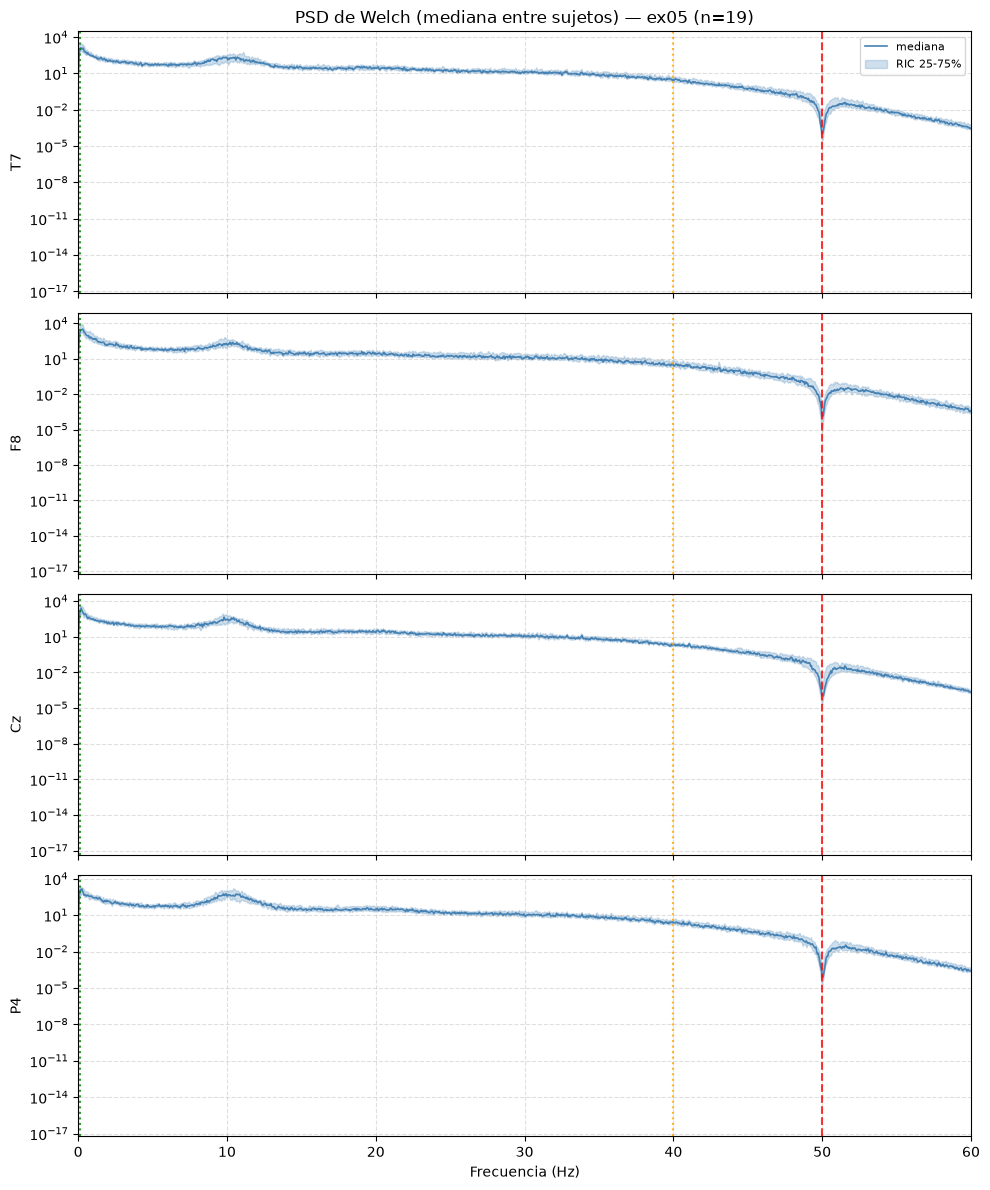

In [6]:
psd_acumulado = {canal: [] for canal in canales}
freq = None

for nombre in archivos_ex06:
    path = os.path.join(ruta_datos, nombre)
    df = pd.read_csv(path, index_col=0)
    f, psd_dict = PSD.welch_eeg(df, fs, nperseg=nperseg, canales=canales)
    if freq is None:
        freq = f

    for canal in canales:
        psd_acumulado[canal].append(psd_dict[canal])

# Convertir a matrices (sujetos x frecuencias) y calcular media/mediana + dispersión
fig, axes = plt.subplots(len(canales), 1, figsize=(10, 3 * len(canales)), sharex=True)

for ax, canal in zip(axes, canales):
    matriz = np.array(psd_acumulado[canal])  # shape: (n_sujetos, n_freq)

    mediana06 = np.median(matriz, axis=0)
    p25 = np.percentile(matriz, 25, axis=0)
    p75 = np.percentile(matriz, 75, axis=0)

    ax.semilogy(freq, mediana06, color="steelblue", lw=1.2, label="mediana")
    ax.fill_between(freq, p25, p75, color="steelblue", alpha=0.25, label="RIC 25-75%")

    for f_ref, (c, ls) in eeg.REFS_DEFAULT.items():
        ax.axvline(f_ref, color=c, ls=ls, alpha=0.8)
    ax.set_ylabel(canal)
    ax.set_xlim(0, 60)
    ax.grid(True, which="both", ls="--", alpha=0.4)

axes[0].set_title(f"PSD de Welch (mediana entre sujetos) — ex05 (n={len(archivos_ex06)})")
axes[0].legend(fontsize=8)
axes[-1].set_xlabel("Frecuencia (Hz)")
plt.tight_layout()
plt.show()

## 3.4 Calculo de potencia por bandas

Luego con estas medianas encuentro las potencias por bandas para luego realizar un analisis

Las bandas son 
- Delta (0,5 a 4Hz)
- Theta (4 a 8Hz)
- Alfa (8 a 12Hz)
- Beta (12 a 30Hz)
- Gama (30 a 100 HAz)
 
Y se estudia la potencia relativa ya que al normalizar, las 5 bandas de cada registro suman (aproximadamente) 1 entonces comparamos “porcentaje de energía en cada banda” entre condiciones, que es una medida mucho más estable y es el estándar en la literatura de EEG para este tipo de comparación (incluido el paper de Rajbdad et al.).

La logica de este codigo se encuentra en /analisis_PSD.py y luego se realiza una tabla comparativa con los datos:

In [7]:
BANDAS = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alfa":  (8, 13),
    "beta":  (13, 30),
    "gamma": (30, 40),
}
resultado_ex05 = PSD.potencia_por_banda(freq,mediana05,BANDAS)
resultado_ex06 = PSD.potencia_por_banda(freq,mediana06,BANDAS)
df_comparacion = pd.DataFrame({
    "nativo (ex05)": resultado_ex05,
    "no_nativo (ex06)": resultado_ex06,
})

df_comparacion["diferencia"] = df_comparacion["no_nativo (ex06)"] - df_comparacion["nativo (ex05)"]
df_comparacion_pct = (df_comparacion * 100).round(2)
df_comparacion_pct.index = df_comparacion_pct.index.str.replace("_rel", "")
df_comparacion_pct.columns = ["nativo (%)", "no nativo (%)", "diferencia (%)"]
print(df_comparacion_pct)

       nativo (%)  no nativo (%)  diferencia (%)
delta       19.67          22.60            2.93
theta        8.60           9.02            0.42
alfa        52.04          48.98           -3.05
beta        16.53          16.19           -0.34
gamma        2.78           2.73           -0.05


## 3.5 Analisis

